# **Laptop Price Analysis – Capstone Project**

## **Problem Statement**
Two laptops that look almost the same can have a very different price. In this project we try to find out which specifications (RAM, processor, storage, screen, brand and so on) really decide the price of a laptop, and whether we can tell if a laptop is Budget, Mid-range or Premium just from its specs.

## **About the Dataset**
The dataset has 1,275 laptops from 19 brands. It is based on the Laptop Price dataset by Muhammet Varli (Kaggle). The original prices were in euros, so we converted them to rupees using 1 EUR = ₹110. We also removed duplicate listings and split the text columns (screen resolution, CPU, memory) into proper numeric columns so they are easy to analyse.

## **Objective**
1. Explore the data and find out what affects the laptop price.
2. Use the same data later in Orange to predict the price (regression) and the price category (classification).


# **Importing Essential Libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# **Loading the Dataset**
Run the cell below and select the file **laptop_price_inr_cleaned.csv** from your computer. You can also read it from Google Drive using the commented lines.


In [4]:
# Option 1: upload the file from your computer (works in Google Colab)
try:
    from google.colab import files
    uploaded = files.upload()          # select laptop_price_inr_cleaned.csv
except ImportError:
    pass                               # (running outside Colab - file is already in the folder)

laptop1 = pd.read_csv('laptop_price_inr_cleaned.csv')

# Option 2: read from Google Drive (remove the # to use)
# from google.colab import drive
# drive.mount('/content/drive')
# laptop1 = pd.read_csv('/content/drive/MyDrive/<your folder>/laptop_price_inr_cleaned.csv')

Saving laptop_price_inr_cleaned.csv to laptop_price_inr_cleaned (2).csv


# **Creating a Copy of our Dataset**

In [5]:
# creating a copy so that the original data stays safe
laptop = laptop1.copy()

# **Overview of the Dataset**

In [6]:
# Data exploration (total rows and columns)
print(f"We have {laptop.shape[0]} Rows and {laptop.shape[1]} Columns.")

We have 1275 Rows and 25 Columns.


In [7]:
# Top 10 rows
laptop.head(10)

,Company,Product,TypeName,Inches,Screen_Width,Screen_Height,PPI,Touchscreen,IPS_Panel,Cpu_Brand,...,Flash_GB,Hybrid_GB,Total_Storage_GB,Storage_Type,Gpu_Brand,OpSys,OS_Family,Weight_kg,Price_INR,Price_Category
0,Apple,MacBook Pro,Ultrabook,13.3,2560,1600,227.0,0,1,Intel,...,0,0,128,SSD,Intel,macOS,macOS,1.37,147366,Premium
1,Apple,Macbook Air,Ultrabook,13.3,1440,900,127.7,0,0,Intel,...,128,0,128,Flash,Intel,macOS,macOS,1.34,98883,Mid-range
2,HP,250 G6,Notebook,15.6,1920,1080,141.2,0,0,Intel,...,0,0,256,SSD,Intel,No OS,No OS,1.86,63250,Mid-range
3,Apple,MacBook Pro,Ultrabook,15.4,2880,1800,220.5,0,1,Intel,...,0,0,512,SSD,AMD,macOS,macOS,1.83,279120,Premium
4,Apple,MacBook Pro,Ultrabook,13.3,2560,1600,227.0,0,1,Intel,...,0,0,256,SSD,Intel,macOS,macOS,1.37,198396,Premium
5,Acer,Aspire 3,Notebook,15.6,1366,768,100.5,0,0,AMD,...,0,0,500,HDD,AMD,Windows 10,Windows,2.10,44000,Budget
6,Apple,MacBook Pro,Ultrabook,15.4,2880,1800,220.5,0,1,Intel,...,256,0,256,Flash,Intel,macOS,macOS,2.04,235397,Premium
7,Apple,Macbook Air,Ultrabook,13.3,1440,900,127.7,0,0,Intel,...,256,0,256,Flash,Intel,macOS,macOS,1.34,127457,Premium
8,Asus,ZenBook UX430UN,Ultrabook,14.0,1920,1080,157.4,0,0,Intel,...,0,0,512,SSD,Nvidia,Windows 10,Windows,1.30,164450,Premium
9,Acer,Swift 3,Ultrabook,14.0,1920,1080,157.4,0,1,Intel,...,0,0,256,SSD,Intel,Windows 10,Windows,1.60,84700,Mid-range


In [8]:
# Last 10 rows
laptop.tail(10)

,Company,Product,TypeName,Inches,Screen_Width,Screen_Height,PPI,Touchscreen,IPS_Panel,Cpu_Brand,...,Flash_GB,Hybrid_GB,Total_Storage_GB,Storage_Type,Gpu_Brand,OpSys,OS_Family,Weight_kg,Price_INR,Price_Category
1265,Lenovo,IdeaPad Y700-15ISK,Notebook,15.6,1920,1080,141.2,0,1,Intel,...,0,0,1000,HDD,Nvidia,Windows 10,Windows,2.60,98890,Mid-range
1266,HP,Pavilion 15-AW003nv,Notebook,15.6,1920,1080,141.2,0,0,AMD,...,0,1000,1000,Hybrid,AMD,Windows 10,Windows,2.04,60499,Mid-range
1267,Dell,Inspiron 3567,Notebook,15.6,1366,768,100.5,0,0,Intel,...,0,0,1000,HDD,AMD,Linux,Linux,2.30,88659,Mid-range
1268,HP,Stream 11-Y000na,Netbook,11.6,1366,768,135.1,0,0,Intel,...,32,0,32,Flash,Intel,Windows 10,Windows,1.17,22990,Budget
1269,Asus,X556UJ-XO044T (i7-6500U/4GB/500GB/GeForce,Notebook,15.6,1366,768,100.5,0,0,Intel,...,0,0,500,HDD,Nvidia,Windows 10,Windows,2.20,79235,Mid-range
1270,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,1920,1080,157.4,1,1,Intel,...,0,0,128,SSD,Intel,Windows 10,Windows,1.80,70180,Mid-range
1271,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,3200,1800,276.1,1,1,Intel,...,0,0,512,SSD,Intel,Windows 10,Windows,1.30,164890,Premium
1272,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366,768,111.9,0,0,Intel,...,64,0,64,Flash,Intel,Windows 10,Windows,1.50,25190,Budget
1273,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366,768,100.5,0,0,Intel,...,0,0,1000,HDD,AMD,Windows 10,Windows,2.19,84040,Mid-range
1274,Asus,X553SA-XX031T (N3050/4GB/500GB/W10),Notebook,15.6,1366,768,100.5,0,0,Intel,...,0,0,500,HDD,Intel,Windows 10,Windows,2.20,40590,Budget


In [9]:
# Basic statistics of the numeric columns
laptop.describe()

,Inches,Screen_Width,Screen_Height,PPI,Touchscreen,IPS_Panel,Cpu_GHz,Ram_GB,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB,Total_Storage_GB,Weight_kg,Price_INR
count,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000
mean,15.022902,1900.043922,1073.904314,146.983765,0.147451,0.280000,2.302980,8.440784,185.960784,413.458824,4.505098,7.457255,611.381961,2.040525,124846.600784
std,1.429470,493.346186,283.883940,42.981044,0.354694,0.449175,0.503846,5.097809,186.530905,517.783022,30.488368,84.919208,469.797866,0.669196,77082.777050
min,10.100000,1366.000000,768.000000,90.600000,0.000000,0.000000,0.900000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,0.690000,19140.000000
25%,14.000000,1920.000000,1080.000000,127.300000,0.000000,0.000000,2.000000,4.000000,0.000000,0.000000,0.000000,0.000000,256.000000,1.500000,66990.000000
50%,15.600000,1920.000000,1080.000000,141.200000,0.000000,0.000000,2.500000,8.000000,256.000000,0.000000,0.000000,0.000000,500.000000,2.040000,108790.000000
75%,15.600000,1920.000000,1080.000000,157.400000,0.000000,1.000000,2.700000,8.000000,256.000000,1000.000000,0.000000,0.000000,1000.000000,2.310000,164615.000000
max,18.400000,3840.000000,2160.000000,352.500000,1.000000,1.000000,3.600000,64.000000,1024.000000,2000.000000,512.000000,1000.000000,2512.000000,4.700000,670890.000000


In [10]:
# Basic statistics of the text (categorical) columns
laptop.describe(include='object')

,Company,Product,TypeName,Cpu_Brand,Cpu_Series,Storage_Type,Gpu_Brand,OpSys,OS_Family,Price_Category
count,1275,1275,1275,1275,1275,1275,1275,1275,1275,1275
unique,19,618,6,3,13,7,4,8,6,3
top,Dell,XPS 13,Notebook,Intel,Core i7,SSD,Intel,Windows 10,Windows,Premium
freq,291,30,707,1214,515,635,704,1048,1101,567


In [11]:
# List of columns
list(laptop.columns)

['Company',
 'Product',
 'TypeName',
 'Inches',
 'Screen_Width',
 'Screen_Height',
 'PPI',
 'Touchscreen',
 'IPS_Panel',
 'Cpu_Brand',
 'Cpu_Series',
 'Cpu_GHz',
 'Ram_GB',
 'SSD_GB',
 'HDD_GB',
 'Flash_GB',
 'Hybrid_GB',
 'Total_Storage_GB',
 'Storage_Type',
 'Gpu_Brand',
 'OpSys',
 'OS_Family',
 'Weight_kg',
 'Price_INR',
 'Price_Category']

In [12]:
# Column labels, data types, non-null counts and memory usage
laptop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1275 non-null   object 
 1   Product           1275 non-null   object 
 2   TypeName          1275 non-null   object 
 3   Inches            1275 non-null   float64
 4   Screen_Width      1275 non-null   int64  
 5   Screen_Height     1275 non-null   int64  
 6   PPI               1275 non-null   float64
 7   Touchscreen       1275 non-null   int64  
 8   IPS_Panel         1275 non-null   int64  
 9   Cpu_Brand         1275 non-null   object 
 10  Cpu_Series        1275 non-null   object 
 11  Cpu_GHz           1275 non-null   float64
 12  Ram_GB            1275 non-null   int64  
 13  SSD_GB            1275 non-null   int64  
 14  HDD_GB            1275 non-null   int64  
 15  Flash_GB          1275 non-null   int64  
 16  Hybrid_GB         1275 non-null   int64  


### **Description of the columns**

| Column | Meaning |
|---|---|
| Company | Laptop brand (Dell, HP, Apple ...) |
| Product | Model name |
| TypeName | Category: Notebook, Gaming, Ultrabook, 2 in 1 Convertible, Workstation, Netbook |
| Inches | Screen size in inches |
| Screen_Width, Screen_Height | Screen resolution in pixels |
| PPI | Pixels per inch (sharpness of the screen) |
| Touchscreen | 1 = touchscreen, 0 = not |
| IPS_Panel | 1 = IPS display, 0 = not |
| Cpu_Brand, Cpu_Series, Cpu_GHz | Processor brand, family (Core i3/i5/i7 ...) and clock speed |
| Ram_GB | RAM in GB |
| SSD_GB, HDD_GB, Flash_GB, Hybrid_GB | Storage in GB by type |
| Total_Storage_GB | Total storage in GB |
| Storage_Type | SSD, HDD, SSD+HDD, Flash, Hybrid ... |
| Gpu_Brand | Graphics card brand |
| OpSys, OS_Family | Operating system (detailed and grouped) |
| Weight_kg | Weight in kg |
| **Price_INR** | **Price in Indian Rupees (target for regression)** |
| **Price_Category** | **Budget (< ₹60,000), Mid-range (₹60,000 - ₹1,20,000), Premium (> ₹1,20,000) (target for classification)** |

# **Checking Unique Contents**

In [13]:
laptop['Company'].unique()

array(['Apple', 'HP', 'Acer', 'Asus', 'Dell', 'Lenovo', 'Chuwi', 'MSI',
       'Microsoft', 'Toshiba', 'Huawei', 'Xiaomi', 'Vero', 'Razer',
       'Mediacom', 'Samsung', 'Google', 'Fujitsu', 'LG'], dtype=object)

In [14]:
laptop['TypeName'].unique()

array(['Ultrabook', 'Notebook', 'Netbook', 'Gaming', '2 in 1 Convertible',
       'Workstation'], dtype=object)

In [15]:
laptop['Cpu_Series'].unique()

array(['Core i5', 'Core i7', 'A-Series', 'Core i3', 'Core M', 'Atom',
       'E-Series', 'Celeron', 'Ryzen', 'Pentium', 'FX', 'Xeon', 'Cortex'],
      dtype=object)

In [16]:
laptop['Ram_GB'].unique()

array([ 8, 16,  4,  2, 12,  6, 32, 24, 64])

In [17]:
laptop['Storage_Type'].unique()

array(['SSD', 'Flash', 'HDD', 'SSD+HDD', 'Hybrid', 'HDD+Flash',
       'SSD+Hybrid'], dtype=object)

In [18]:
laptop['Gpu_Brand'].unique()

array(['Intel', 'AMD', 'Nvidia', 'ARM'], dtype=object)

In [19]:
laptop['OS_Family'].unique()

array(['macOS', 'No OS', 'Windows', 'Linux', 'Android', 'Chrome OS'],
      dtype=object)

In [20]:
laptop['Price_Category'].unique()

array(['Premium', 'Mid-range', 'Budget'], dtype=object)

# **Checking for Missing / Null Values and Duplicates**

In [21]:
# check for missing values
laptop.isna().sum(axis=0)

,0
Company,0
Product,0
TypeName,0
Inches,0
Screen_Width,0
Screen_Height,0
PPI,0
Touchscreen,0
IPS_Panel,0
Cpu_Brand,0


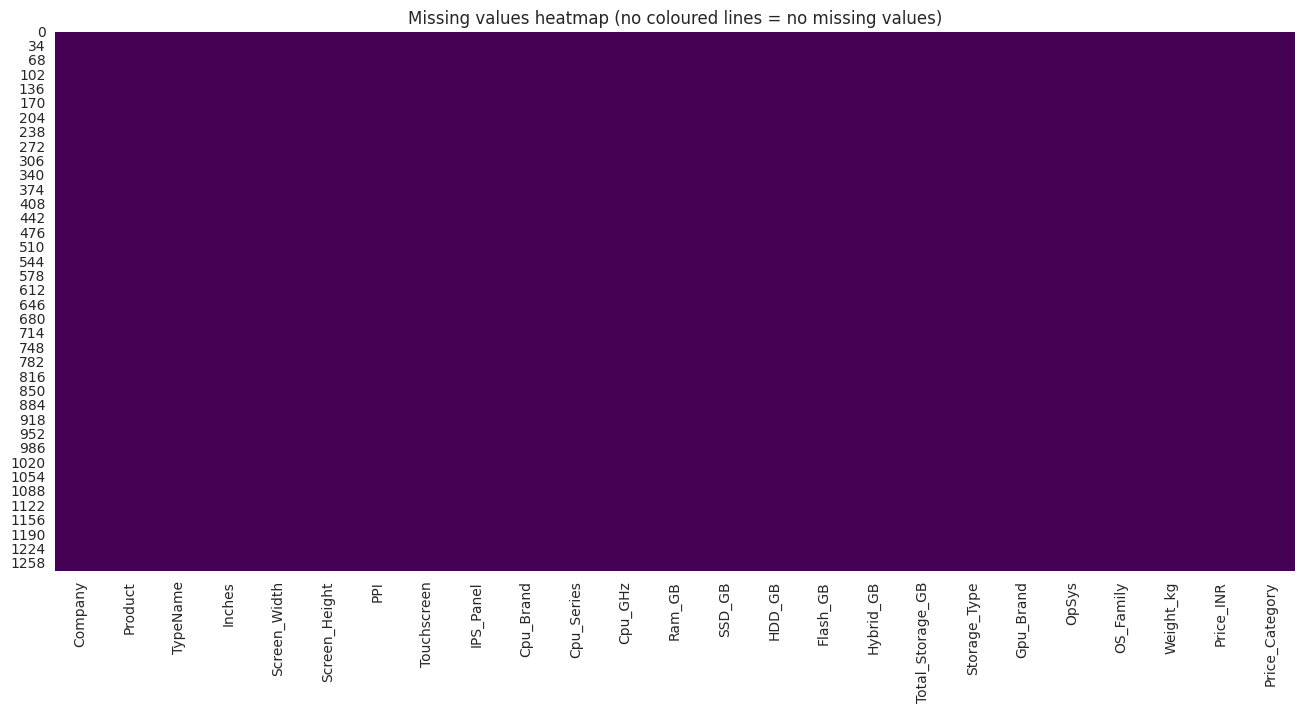

In [22]:
# visualise missing values using a heatmap
plt.figure(figsize=(16, 7))
sns.heatmap(laptop.isnull(), cbar=False, cmap='viridis')
plt.title('Missing values heatmap (no coloured lines = no missing values)')
plt.show()

In [23]:
# check for duplicate rows
print('Duplicate rows:', laptop.duplicated().sum())

Duplicate rows: 0


### ***Observation***
### ***There are no missing values and no duplicate rows in the data.***
### ***The data was already cleaned before this step (prices converted to rupees, duplicate listings removed, text columns changed to numbers), so we can start the analysis directly.***

# **Univariate Analysis**
* In univariate analysis we study **one feature at a time** to understand its distribution.

## ***1] How are laptop prices distributed?***

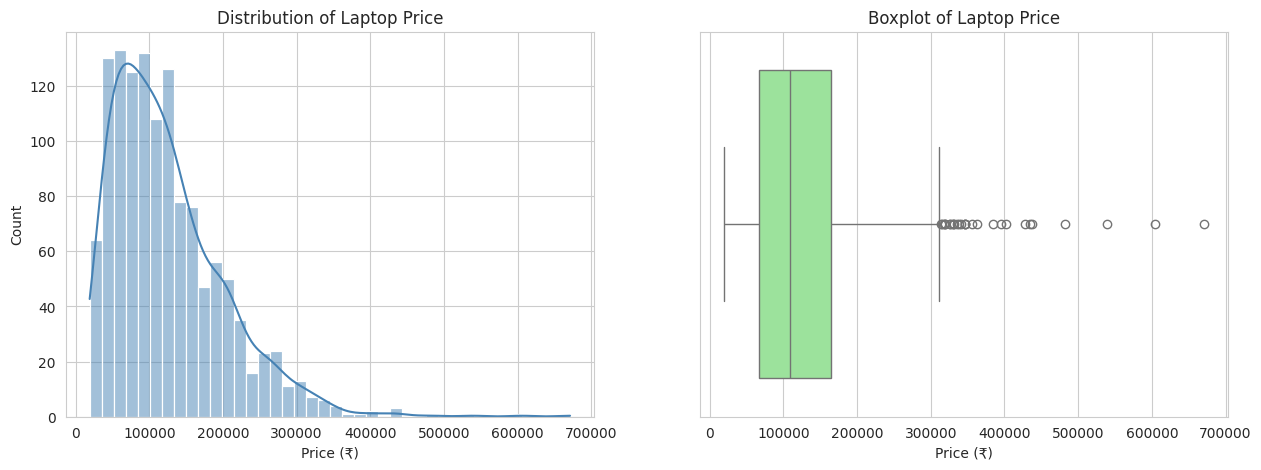

Average price : 124847
Median price  : 108790
Minimum price : 19140
Maximum price : 670890
Skewness      : 1.51


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(laptop['Price_INR'], bins=40, kde=True, color='steelblue', ax=ax[0])
ax[0].set_title('Distribution of Laptop Price')
ax[0].set_xlabel('Price (₹)')

sns.boxplot(x=laptop['Price_INR'], color='lightgreen', ax=ax[1])
ax[1].set_title('Boxplot of Laptop Price')
ax[1].set_xlabel('Price (₹)')
plt.show()

print('Average price :', round(laptop['Price_INR'].mean()))
print('Median price  :', round(laptop['Price_INR'].median()))
print('Minimum price :', laptop['Price_INR'].min())
print('Maximum price :', laptop['Price_INR'].max())
print('Skewness      :', round(laptop['Price_INR'].skew(), 2))

### ***Observation***
### ***Most laptops are priced between about ₹67,000 and ₹1,65,000.***
### ***The graph is skewed to the right (skewness 1.51) because a few laptops are very expensive.***
### ***Because of them the average price (about ₹1.25 lakh) is higher than the median (about ₹1.09 lakh).***
### ***The cheapest laptop is ₹19,140 and the costliest is ₹6,70,890.***

## ***2] Which laptop brands have the most models in the data?***

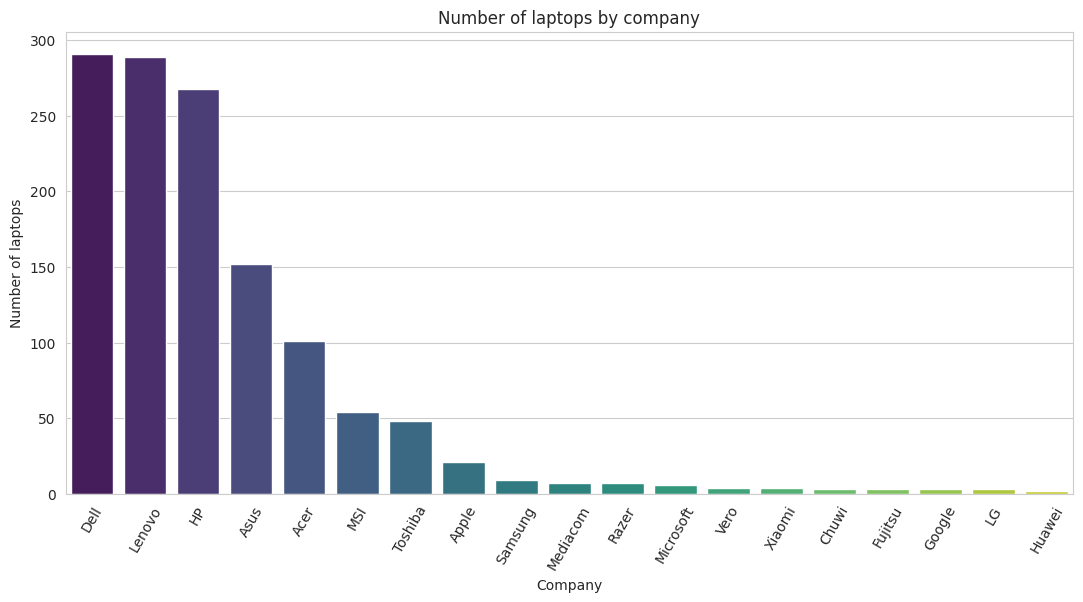

Company
Dell      22.8
Lenovo    22.7
HP        21.0
Asus      11.9
Acer       7.9
Name: count, dtype: float64


In [25]:
company_count = laptop['Company'].value_counts()

plt.figure(figsize=(13, 6))
sns.barplot(x=company_count.index, y=company_count.values, palette='viridis')
plt.xticks(rotation=60)
plt.xlabel('Company')
plt.ylabel('Number of laptops')
plt.title('Number of laptops by company')
plt.show()

print((company_count.head(5) * 100 / len(laptop)).round(1))

### ***Observation***
### ***Dell (291), Lenovo (289) and HP (268) have the most laptops, together about 66% of the data.***
### ***Brands like Huawei, Vero, Chuwi and Google have only 2 to 4 laptops each, so their averages should not be trusted too much.***

## ***3] Which type of laptop is most common?***

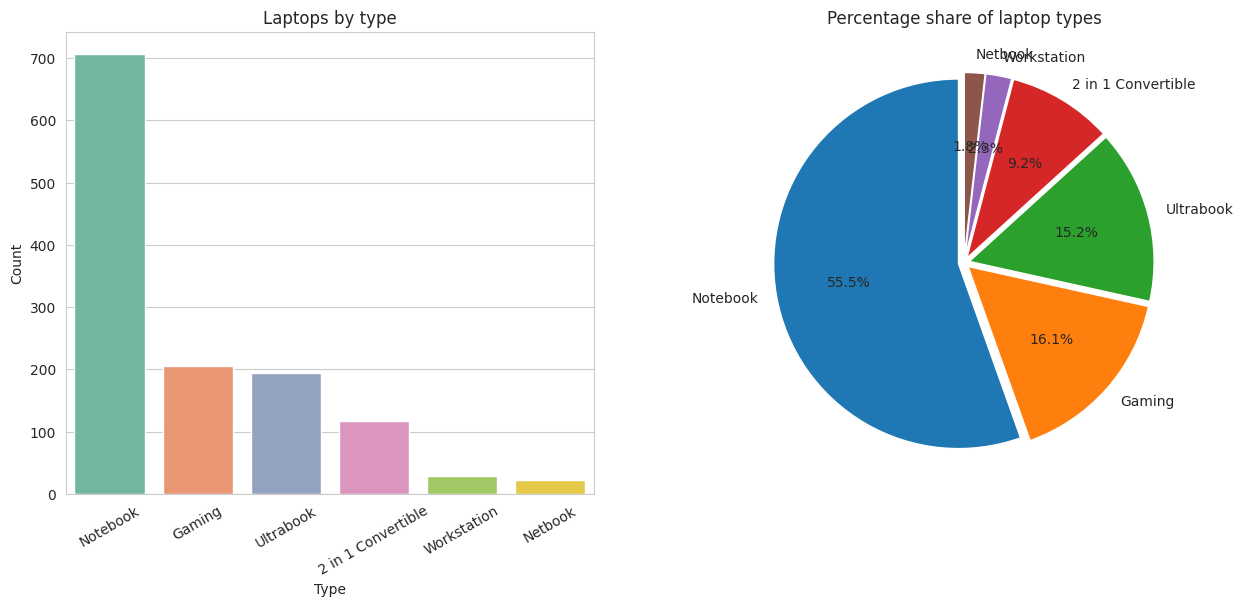

In [26]:
type_count = laptop['TypeName'].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=type_count.index, y=type_count.values, palette='Set2', ax=ax[0])
ax[0].set_title('Laptops by type')
ax[0].set_xlabel('Type')
ax[0].set_ylabel('Count')
ax[0].tick_params(axis='x', rotation=30)

ax[1].pie(type_count.values, labels=type_count.index, autopct='%1.1f%%',
          startangle=90, explode=[0.03]*len(type_count))
ax[1].set_title('Percentage share of laptop types')
plt.show()

### ***Observation***
### ***Notebook is the most common type (about 55%), then Gaming (about 16%) and Ultrabook (about 15%).***
### ***Workstation and Netbook laptops are very few.***

## ***4] Which RAM sizes are most common?***

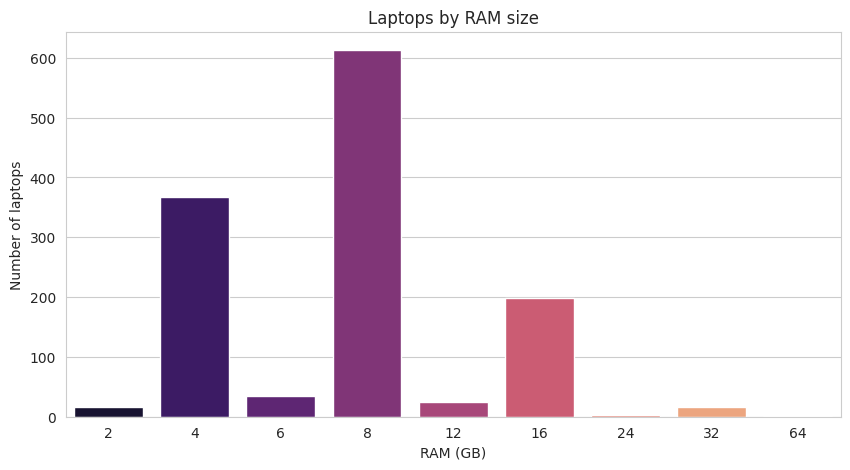

In [27]:
plt.figure(figsize=(10, 5))
ram_count = laptop['Ram_GB'].value_counts().sort_index()
sns.barplot(x=ram_count.index, y=ram_count.values, palette='magma')
plt.xlabel('RAM (GB)')
plt.ylabel('Number of laptops')
plt.title('Laptops by RAM size')
plt.show()

### ***Observation***
### ***8 GB is the most common RAM (613 laptops), then 4 GB (367) and 16 GB (198).***
### ***These three sizes together cover more than 92% of the laptops.***

## ***5] Which processor (CPU) series is most common?***

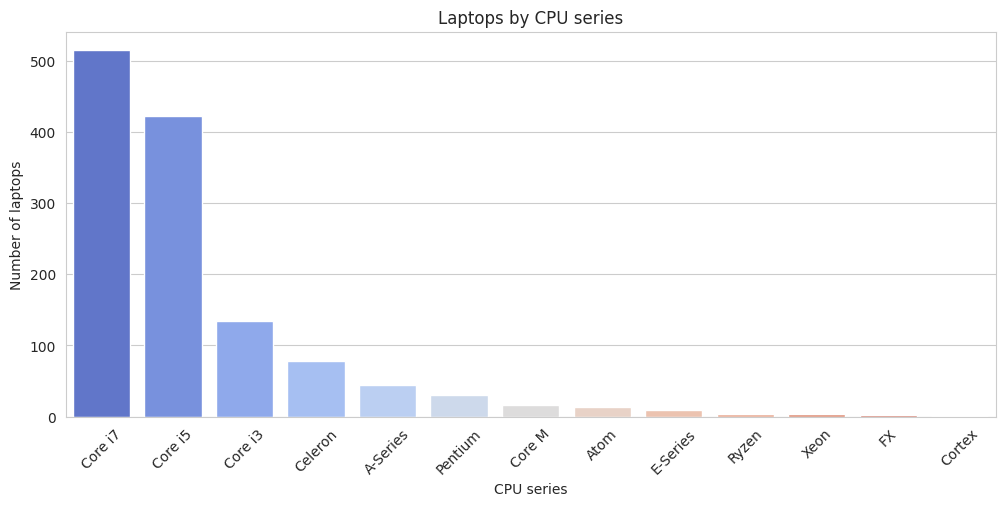

Cpu_Brand
Intel      1214
AMD          60
Samsung       1
Name: count, dtype: int64


In [28]:
plt.figure(figsize=(12, 5))
cpu_count = laptop['Cpu_Series'].value_counts()
sns.barplot(x=cpu_count.index, y=cpu_count.values, palette='coolwarm')
plt.xticks(rotation=45)
plt.xlabel('CPU series')
plt.ylabel('Number of laptops')
plt.title('Laptops by CPU series')
plt.show()

print(laptop['Cpu_Brand'].value_counts())

### ***Observation***
### ***Core i7 (515) and Core i5 (423) are the most common processors.***
### ***About 95% of the laptops have an Intel CPU and only 60 have AMD.***

## ***6] Which storage type is most common?***

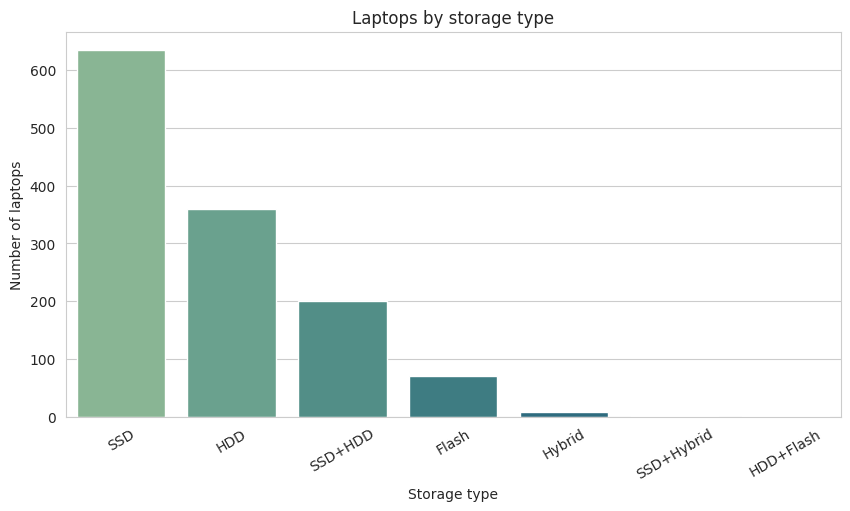

In [29]:
storage_count = laptop['Storage_Type'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=storage_count.index, y=storage_count.values, palette='crest')
plt.xticks(rotation=30)
plt.xlabel('Storage type')
plt.ylabel('Number of laptops')
plt.title('Laptops by storage type')
plt.show()

### ***Observation***
### ***About half of the laptops (635) have only an SSD, 359 have only an HDD and 200 have both.***
### ***Flash and Hybrid storage are very rare.***

## ***7] What is the distribution of screen size, weight, CPU speed and storage?***

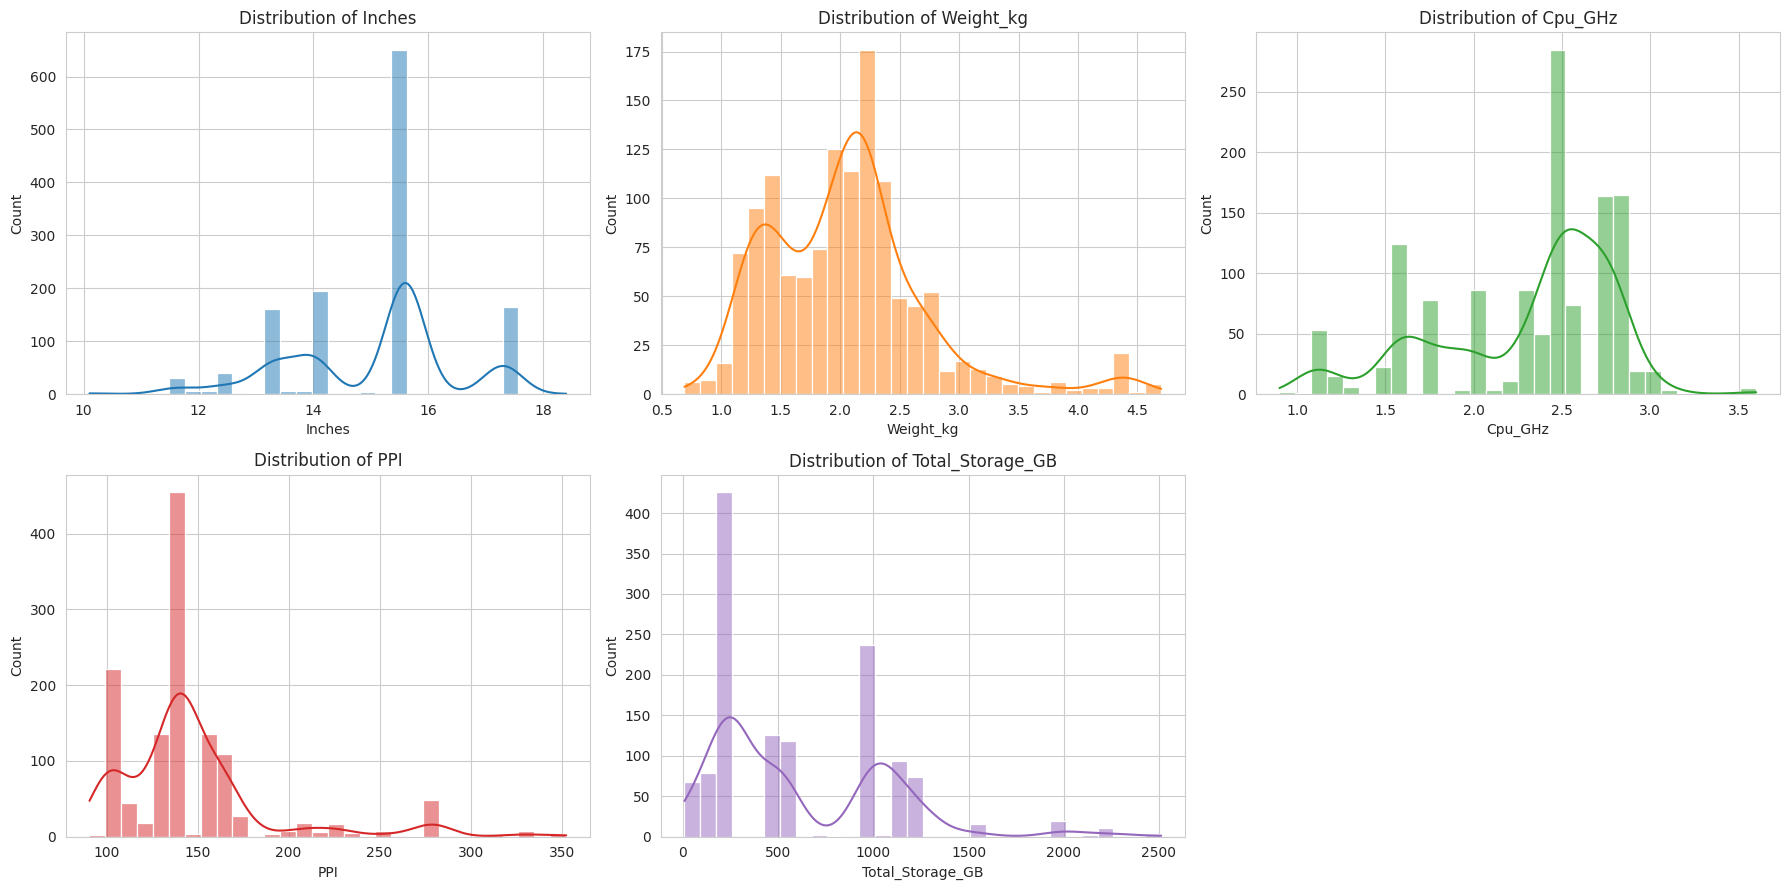

In [30]:
cols = ['Inches', 'Weight_kg', 'Cpu_GHz', 'PPI', 'Total_Storage_GB']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()
for i, c in enumerate(cols):
    sns.histplot(laptop[c], bins=30, kde=True, ax=axes[i], color=sns.color_palette('tab10')[i])
    axes[i].set_title(f'Distribution of {c}')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

### ***Observation***
### ***Most laptops have a 15.6-inch screen (647 laptops) and weigh around 2 kg (average 2.04 kg).***
### ***CPU speed is mostly between 2 and 2.7 GHz.***
### ***PPI is mostly around 140, which means a Full HD screen.***

## ***8] How many laptops are touchscreen / have an IPS panel? Which operating system is most common?***

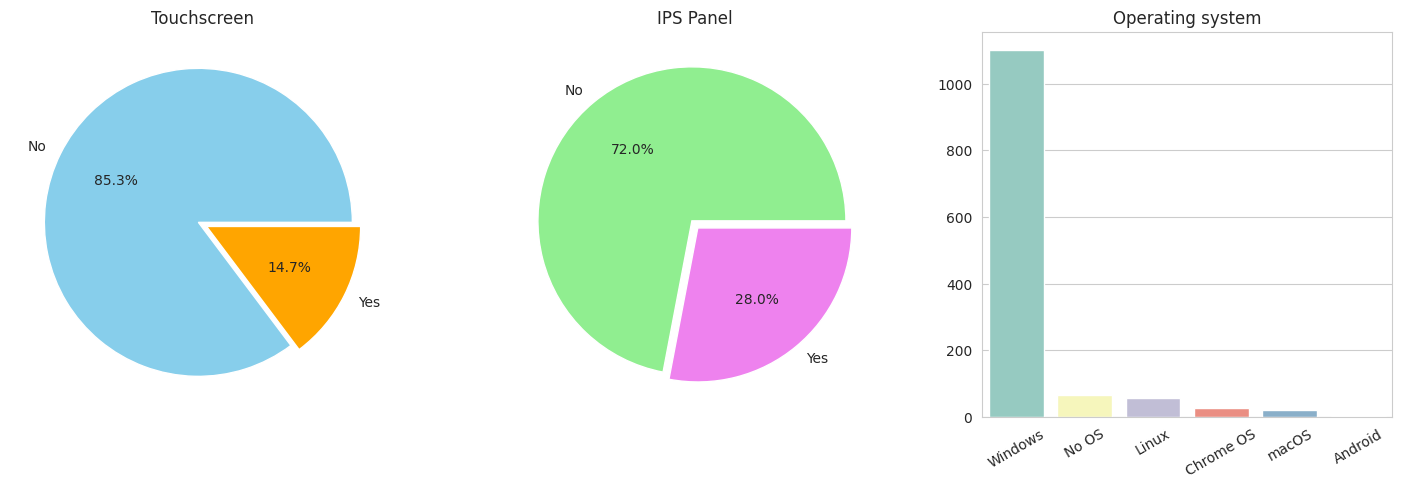

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

laptop['Touchscreen'].map({0: 'No', 1: 'Yes'}).value_counts().plot.pie(
    autopct='%1.1f%%', colors=['skyblue', 'orange'], ax=ax[0], explode=[0.03, 0.03])
ax[0].set_title('Touchscreen'); ax[0].set_ylabel('')

laptop['IPS_Panel'].map({0: 'No', 1: 'Yes'}).value_counts().plot.pie(
    autopct='%1.1f%%', colors=['lightgreen', 'violet'], ax=ax[1], explode=[0.03, 0.03])
ax[1].set_title('IPS Panel'); ax[1].set_ylabel('')

os_count = laptop['OS_Family'].value_counts()
sns.barplot(x=os_count.index, y=os_count.values, palette='Set3', ax=ax[2])
ax[2].set_title('Operating system'); ax[2].set_xlabel(''); ax[2].tick_params(axis='x', rotation=30)
plt.show()

### ***Observation***
### ***Only about 15% of the laptops have a touchscreen and 28% have an IPS panel.***
### ***Windows is installed on 86% of the laptops (1,101). macOS laptops are only 21.***

# **Bivariate Analysis**
* Here we compare **two features** to see how each factor affects the laptop price.

## ***1] Which brands are the most expensive?***

,mean,median,count
Company,,,
Razer,368076.0,318890.0,7
LG,230890.0,230890.0,3
MSI,190180.0,175890.0,54
Google,184543.0,171490.0,3
Microsoft,177354.0,172645.0,6
Apple,172062.0,147366.0,21
Huawei,156640.0,156640.0,2
Samsung,155479.0,181390.0,9
Toshiba,139459.0,133265.0,48


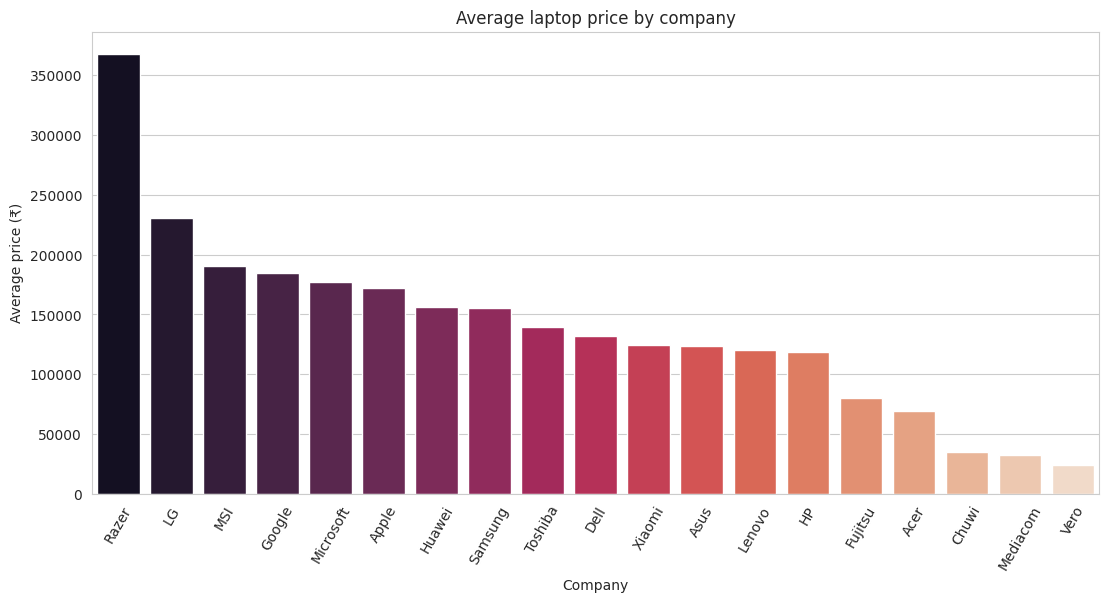

In [32]:
brand_price = (laptop.groupby('Company')['Price_INR']
               .agg(['mean', 'median', 'count'])
               .round(0)
               .sort_values('mean', ascending=False))
display(brand_price)

plt.figure(figsize=(13, 6))
sns.barplot(x=brand_price.index, y=brand_price['mean'], palette='rocket')
plt.xticks(rotation=60)
plt.xlabel('Company')
plt.ylabel('Average price (₹)')
plt.title('Average laptop price by company')
plt.show()

### ***Observation***
### ***Razer has the highest average price (about ₹3.68 lakh), but it has only 7 models.***
### ***After that come LG, MSI (₹1.90 lakh), Google, Microsoft and Apple (₹1.72 lakh).***
### ***Acer is the cheapest of the big brands (₹69,681). Vero, Mediacom and Chuwi are the cheapest overall.***
### ***Dell, Asus, Lenovo and HP are close to each other at around ₹1.2 to ₹1.3 lakh.***

## ***2] How does laptop type affect the price?***

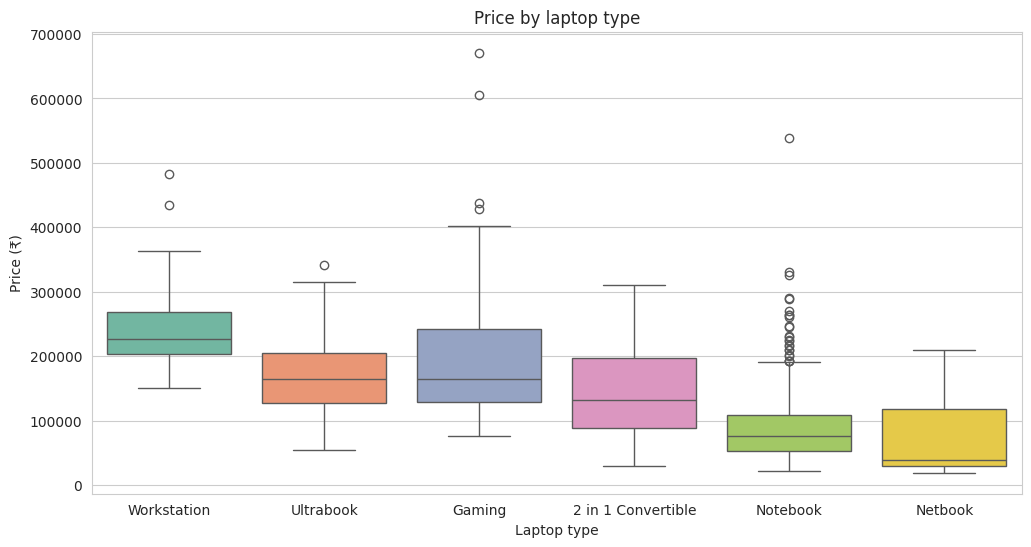

,mean,median,count
TypeName,,,
Workstation,250840.0,227139.0,29
Gaming,190452.0,164208.0,205
Ultrabook,171234.0,164890.0,194
2 in 1 Convertible,141869.0,131890.0,117
Notebook,86762.0,76450.0,707
Netbook,74072.0,39050.0,23


In [33]:
order = laptop.groupby('TypeName')['Price_INR'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(x='TypeName', y='Price_INR', data=laptop, order=order, palette='Set2')
plt.xlabel('Laptop type')
plt.ylabel('Price (₹)')
plt.title('Price by laptop type')
plt.show()

laptop.groupby('TypeName')['Price_INR'].agg(['mean', 'median', 'count']).round(0).sort_values('mean', ascending=False)

### ***Observation***
### ***Workstations are the costliest (average ₹2.51 lakh), followed by Gaming (₹1.90 lakh) and Ultrabook (₹1.71 lakh).***
### ***Notebook is the most common type and also one of the cheapest (₹86,762).***

## ***3] Does more RAM mean a higher price?***

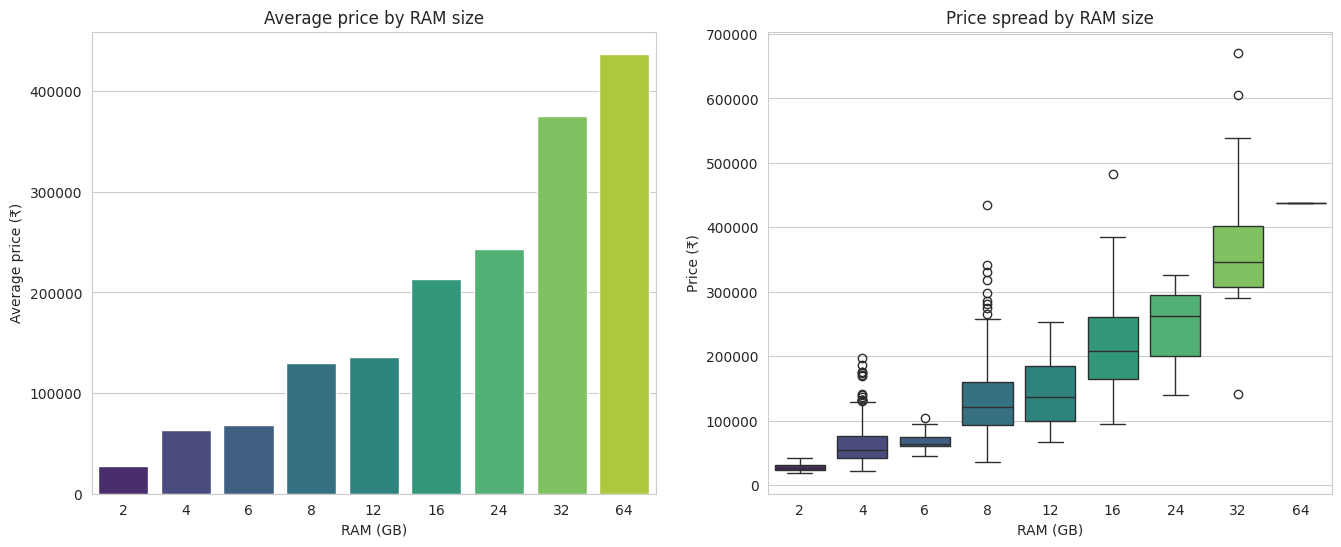

Correlation between RAM and Price: 0.74


In [34]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

ram_price = laptop.groupby('Ram_GB')['Price_INR'].mean()
sns.barplot(x=ram_price.index, y=ram_price.values, palette='viridis', ax=ax[0])
ax[0].set_title('Average price by RAM size')
ax[0].set_xlabel('RAM (GB)'); ax[0].set_ylabel('Average price (₹)')

sns.boxplot(x='Ram_GB', y='Price_INR', data=laptop, palette='viridis', ax=ax[1])
ax[1].set_title('Price spread by RAM size')
ax[1].set_xlabel('RAM (GB)'); ax[1].set_ylabel('Price (₹)')
plt.show()

print('Correlation between RAM and Price:', round(laptop['Ram_GB'].corr(laptop['Price_INR']), 2))

### ***Observation***
### ***RAM has the strongest relation with price (correlation 0.74).***
### ***Average price by RAM: 2 GB ₹27,240, 4 GB ₹63,372, 8 GB ₹1.30 lakh, 16 GB ₹2.14 lakh and 32 GB ₹3.75 lakh.***
### ***Every time the RAM doubles, the average price goes up by about 1.6 to 2.3 times.***

## ***4] How does the CPU series affect the price?***

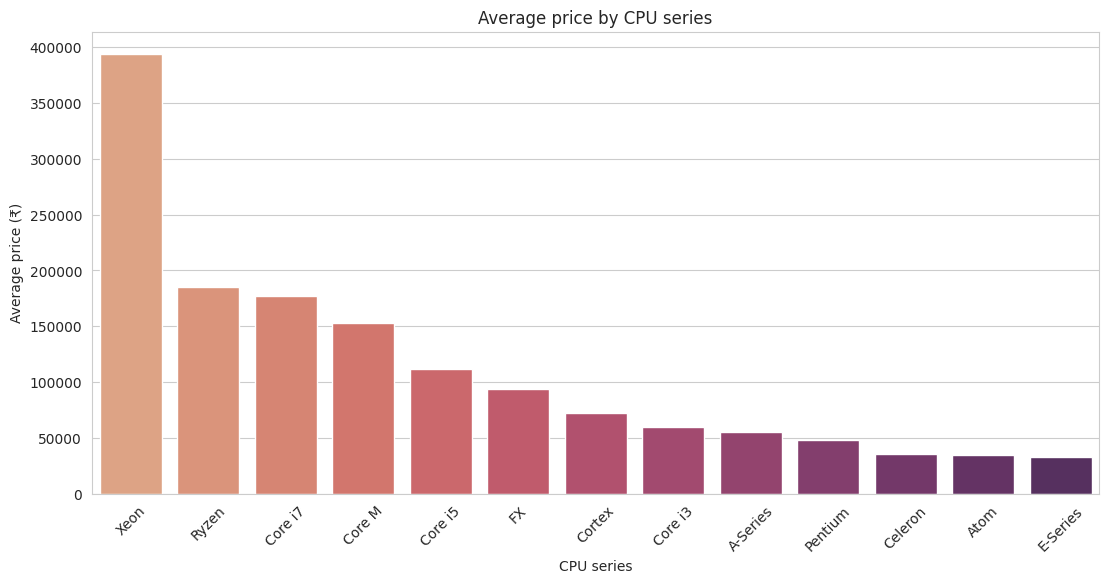

In [35]:
cpu_order = laptop.groupby('Cpu_Series')['Price_INR'].mean().sort_values(ascending=False).index

plt.figure(figsize=(13, 6))
sns.barplot(x='Cpu_Series', y='Price_INR', data=laptop, order=cpu_order, palette='flare', ci=None)
plt.xticks(rotation=45)
plt.xlabel('CPU series')
plt.ylabel('Average price (₹)')
plt.title('Average price by CPU series')
plt.show()

### ***Observation***
### ***Xeon processors are the costliest (₹3.94 lakh), but there are only 4 such laptops.***
### ***Among the common ones, Core i7 averages ₹1.77 lakh, Core i5 ₹1.12 lakh and Core i3 only ₹59,715.***
### ***Celeron, Atom, Pentium and the AMD A/E series are around ₹55,000 or less.***

## ***5] Does CPU clock speed affect the price?***

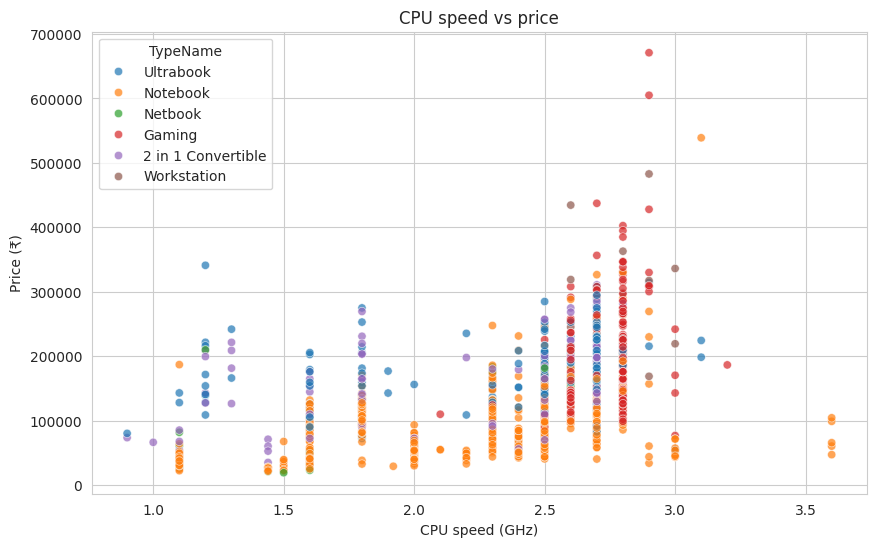

Correlation: 0.43


In [36]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Cpu_GHz', y='Price_INR', data=laptop, hue='TypeName', alpha=0.7)
plt.xlabel('CPU speed (GHz)')
plt.ylabel('Price (₹)')
plt.title('CPU speed vs price')
plt.show()

print('Correlation:', round(laptop['Cpu_GHz'].corr(laptop['Price_INR']), 2))

### ***Observation***
### ***CPU speed has a moderate positive correlation with price (0.43).***
### ***Laptops up to 2 GHz average about ₹82,000, while laptops between 2.5 and 3 GHz average about ₹1.78 lakh.***
### ***Still, the CPU family (i3, i5, i7) matters more than the GHz value alone.***

## ***6] Which storage type gives the highest price? (SSD vs HDD)***

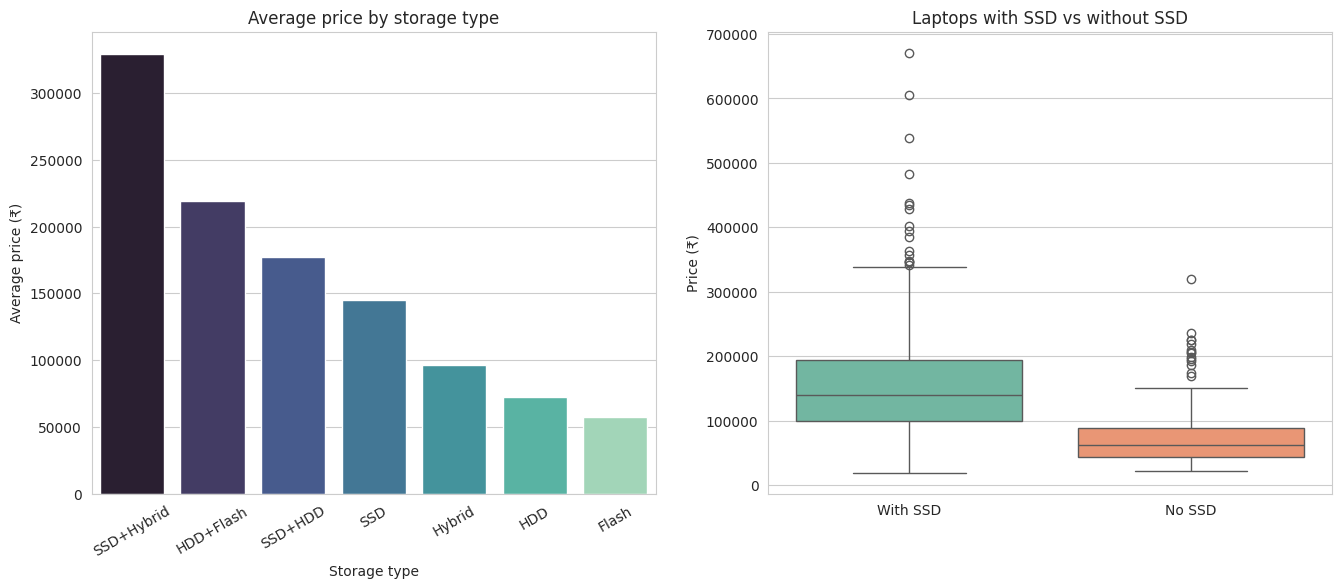

Has_SSD
No SSD       70839.0
With SSD    153109.0
Name: Price_INR, dtype: float64


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

st_order = laptop.groupby('Storage_Type')['Price_INR'].mean().sort_values(ascending=False).index
sns.barplot(x='Storage_Type', y='Price_INR', data=laptop, order=st_order, palette='mako', ci=None, ax=ax[0])
ax[0].set_title('Average price by storage type')
ax[0].set_xlabel('Storage type'); ax[0].set_ylabel('Average price (₹)')
ax[0].tick_params(axis='x', rotation=30)

laptop['Has_SSD'] = np.where(laptop['SSD_GB'] > 0, 'With SSD', 'No SSD')
sns.boxplot(x='Has_SSD', y='Price_INR', data=laptop, palette='Set2', ax=ax[1])
ax[1].set_title('Laptops with SSD vs without SSD')
ax[1].set_xlabel(''); ax[1].set_ylabel('Price (₹)')
plt.show()

print(laptop.groupby('Has_SSD')['Price_INR'].mean().round(0))

### ***Observation***
### ***Laptops with an SSD cost almost double compared to laptops without one (₹1.53 lakh vs ₹70,839).***
### ***SSD+HDD (₹1.77 lakh) is the costliest common combination. HDD-only (₹72,424) and Flash (₹57,674) are cheap.***
### ***The SSD size has a correlation of 0.67 with price but the total storage only 0.16, so the type of storage matters more than how much storage there is.***

## ***7] Does a Touchscreen or an IPS panel make a laptop costlier?***

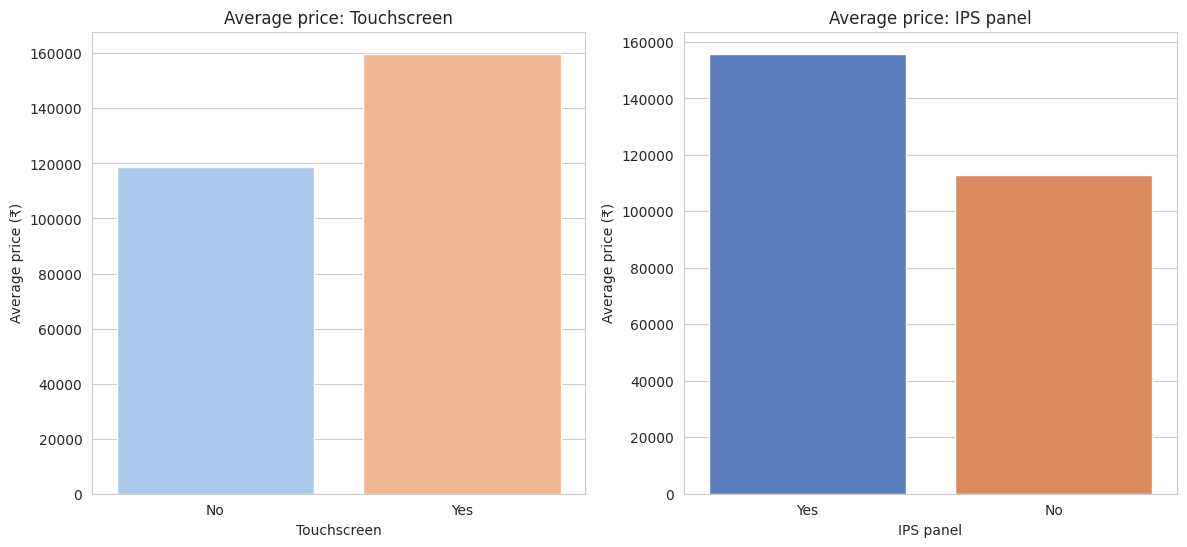

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=laptop['Touchscreen'].map({0: 'No', 1: 'Yes'}), y=laptop['Price_INR'],
            palette='pastel', ci=None, ax=ax[0])
ax[0].set_title('Average price: Touchscreen'); ax[0].set_xlabel('Touchscreen'); ax[0].set_ylabel('Average price (₹)')

sns.barplot(x=laptop['IPS_Panel'].map({0: 'No', 1: 'Yes'}), y=laptop['Price_INR'],
            palette='muted', ci=None, ax=ax[1])
ax[1].set_title('Average price: IPS panel'); ax[1].set_xlabel('IPS panel'); ax[1].set_ylabel('Average price (₹)')
plt.show()

### ***Observation***
### ***Touchscreen laptops cost about ₹41,000 more on average (₹1.60 lakh vs ₹1.19 lakh).***
### ***IPS laptops cost about ₹43,000 more (₹1.56 lakh vs ₹1.13 lakh).***
### ***These features are mostly found in high-end laptops, so a part of this difference comes from the other specs too.***

## ***8] How does screen resolution (PPI) and screen size affect the price?***

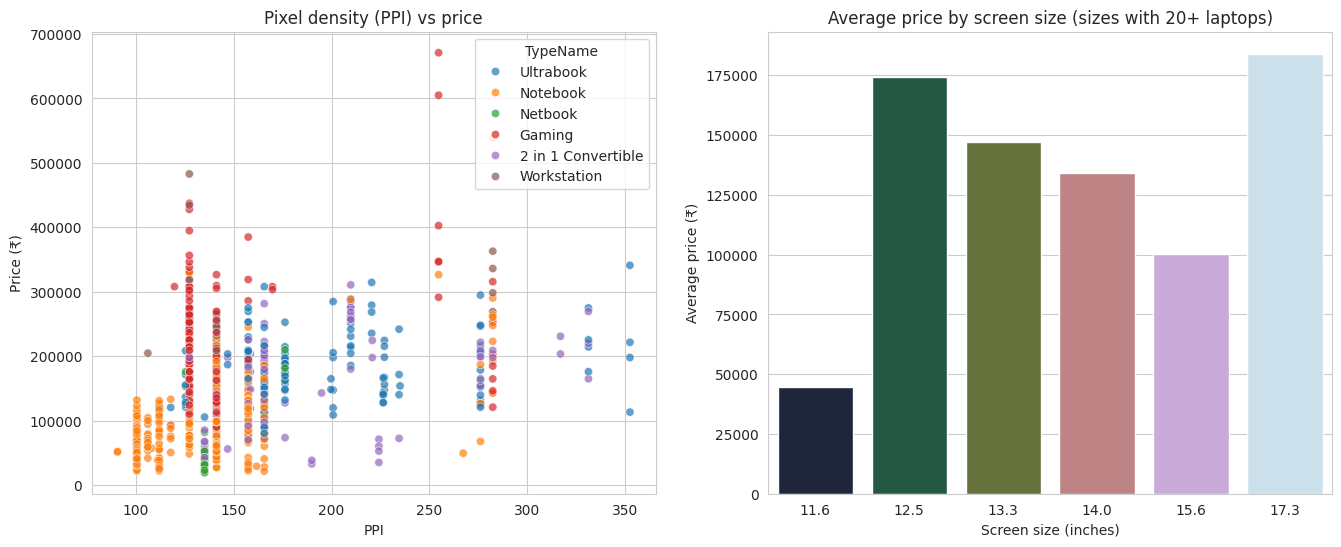

Correlation PPI vs Price   : 0.47
Correlation Inches vs Price: 0.07


In [39]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x='PPI', y='Price_INR', data=laptop, hue='TypeName', alpha=0.7, ax=ax[0])
ax[0].set_title('Pixel density (PPI) vs price')
ax[0].set_xlabel('PPI'); ax[0].set_ylabel('Price (₹)')

inch_price = laptop.groupby('Inches')['Price_INR'].agg(['mean', 'count'])
inch_price = inch_price[inch_price['count'] >= 20]
sns.barplot(x=inch_price.index, y=inch_price['mean'], palette='cubehelix', ax=ax[1])
ax[1].set_title('Average price by screen size (sizes with 20+ laptops)')
ax[1].set_xlabel('Screen size (inches)'); ax[1].set_ylabel('Average price (₹)')
plt.show()

print('Correlation PPI vs Price   :', round(laptop['PPI'].corr(laptop['Price_INR']), 2))
print('Correlation Inches vs Price:', round(laptop['Inches'].corr(laptop['Price_INR']), 2))

### ***Observation***
### ***A sharper screen means a higher price. PPI has a correlation of 0.47 with price.***
### ***Laptops with 4K / QHD+ / Retina type screens average over ₹2.3 lakh, while basic HD (1366x768) screens average only about ₹62,000.***
### ***Screen size alone has almost no relation with price (0.07). The most common size, 15.6-inch, averages only ₹1.00 lakh, while 17.3-inch laptops average ₹1.84 lakh, partly because 57% of them are gaming laptops.***

## ***9] How does the graphics card (GPU) brand affect the price?***

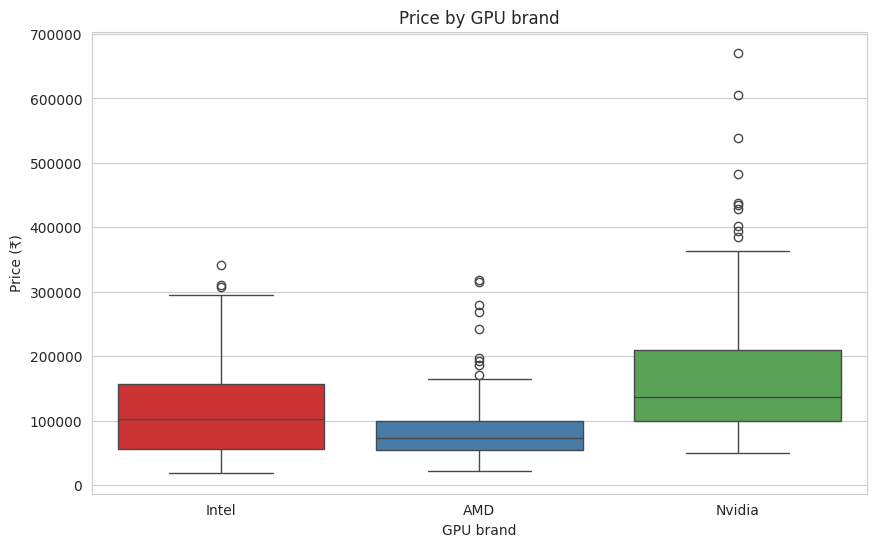

,mean,count
Gpu_Brand,,
AMD,85583.0,174
Intel,112240.0,704
Nvidia,164642.0,396


In [40]:
gpu = laptop[laptop['Gpu_Brand'] != 'ARM']      # ARM has only 1 laptop

plt.figure(figsize=(10, 6))
sns.boxplot(x='Gpu_Brand', y='Price_INR', data=gpu, palette='Set1')
plt.xlabel('GPU brand')
plt.ylabel('Price (₹)')
plt.title('Price by GPU brand')
plt.show()

gpu.groupby('Gpu_Brand')['Price_INR'].agg(['mean', 'count']).round(0)

### ***Observation***
### ***Nvidia laptops are the costliest (average ₹1.65 lakh), then Intel (₹1.12 lakh) and AMD (₹85,583).***
### ***About half of the Nvidia laptops are gaming laptops, which is one reason for the high price.***

## ***10] How does the operating system affect the price?***

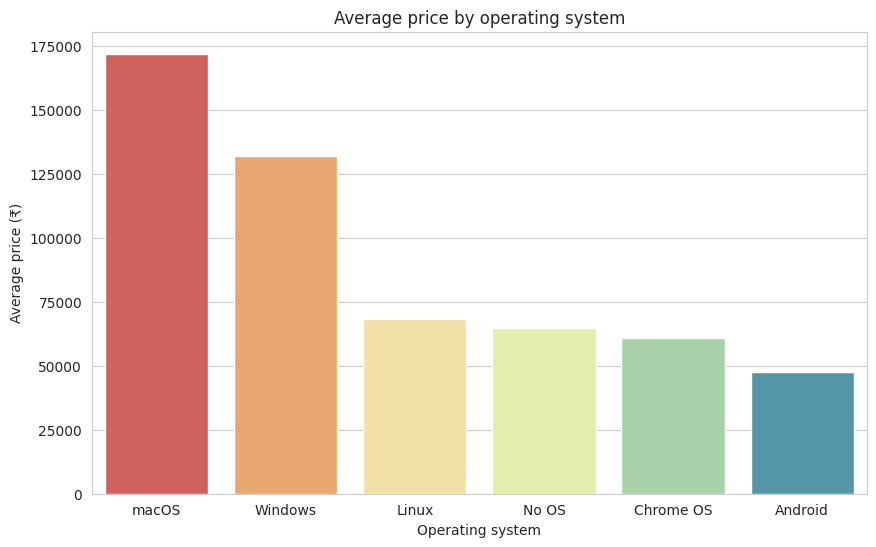

In [41]:
plt.figure(figsize=(10, 6))
os_order = laptop.groupby('OS_Family')['Price_INR'].mean().sort_values(ascending=False).index
sns.barplot(x='OS_Family', y='Price_INR', data=laptop, order=os_order, palette='Spectral', ci=None)
plt.xlabel('Operating system')
plt.ylabel('Average price (₹)')
plt.title('Average price by operating system')
plt.show()

### ***Observation***
### ***macOS laptops are the costliest (₹1.72 lakh), followed by Windows (₹1.32 lakh).***
### ***Laptops with No OS, Linux, Chrome OS or Android average between ₹48,000 and ₹68,000.***

## ***11] Does weight affect the price?***

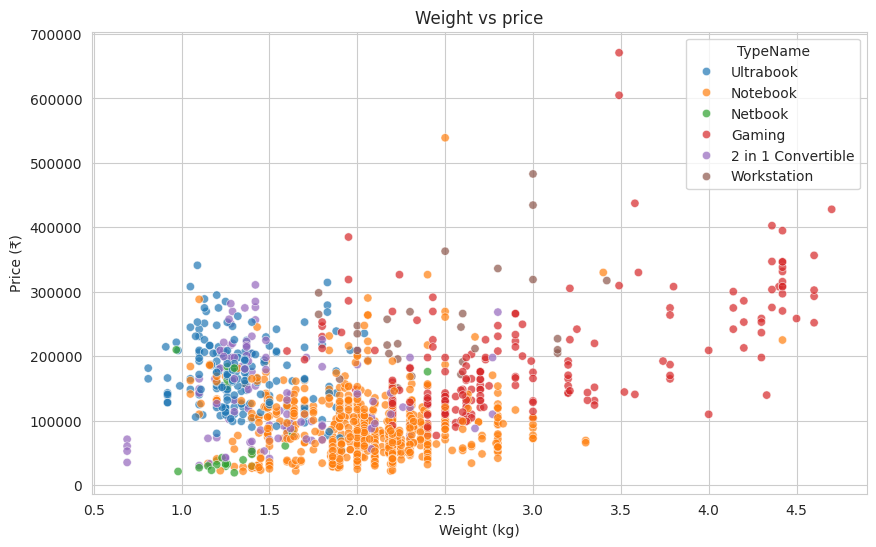

Correlation: 0.21


In [42]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Weight_kg', y='Price_INR', data=laptop, hue='TypeName', alpha=0.7)
plt.xlabel('Weight (kg)')
plt.ylabel('Price (₹)')
plt.title('Weight vs price')
plt.show()

print('Correlation:', round(laptop['Weight_kg'].corr(laptop['Price_INR']), 2))

### ***Observation***
### ***Weight has only a weak relation with price (0.21).***
### ***Ultrabooks are light (average 1.34 kg) and Gaming laptops are heavy (average 2.95 kg), but both are expensive. So weight alone does not tell us the price.***

## ***12] How are the Price Categories (Budget / Mid-range / Premium) distributed?***

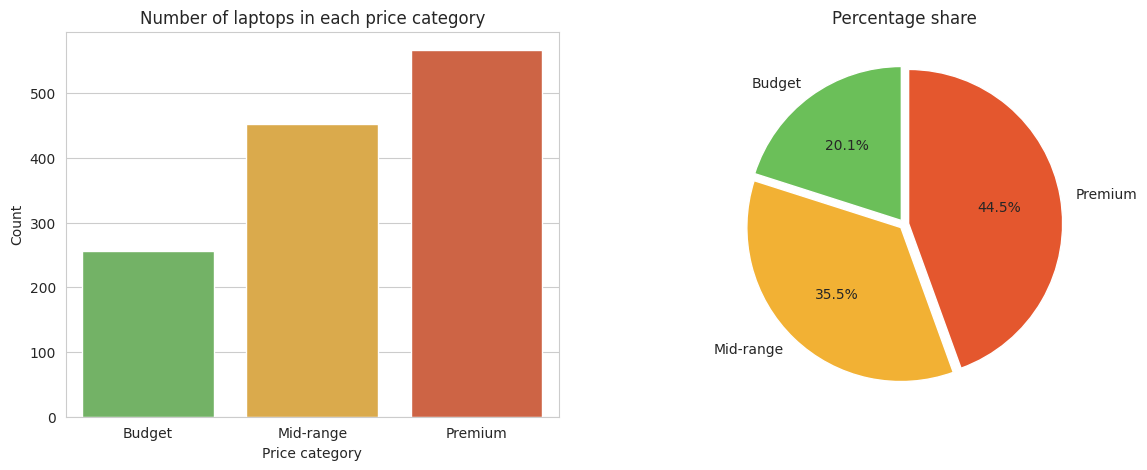

,Ram_GB,SSD_GB,Cpu_GHz,PPI,Weight_kg
Price_Category,,,,,
Budget,4.3,29.2,1.9,119.1,2.0
Mid-range,6.9,127.8,2.3,136.7,2.1
Premium,11.5,303.1,2.5,167.8,2.1


In [43]:
cat_order = ['Budget', 'Mid-range', 'Premium']
cat_count = laptop['Price_Category'].value_counts().reindex(cat_order)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=cat_count.index, y=cat_count.values, palette=['#6bbf59', '#f2b134', '#e4572e'], ax=ax[0])
ax[0].set_title('Number of laptops in each price category')
ax[0].set_xlabel('Price category'); ax[0].set_ylabel('Count')

ax[1].pie(cat_count.values, labels=cat_count.index, autopct='%1.1f%%', startangle=90,
          colors=['#6bbf59', '#f2b134', '#e4572e'], explode=[0.03]*3)
ax[1].set_title('Percentage share')
plt.show()

laptop.groupby('Price_Category')[['Ram_GB', 'SSD_GB', 'Cpu_GHz', 'PPI', 'Weight_kg']].mean().round(1).reindex(cat_order)

### ***Observation***
### ***Premium is the biggest group (567 laptops, 44%), then Mid-range (452, 35%) and Budget (256, 20%).***
### ***The three classes are fairly balanced, which is good for the classification model later.***
### ***An average Premium laptop has 11.5 GB RAM, while a Budget laptop has only 4.3 GB.***

## ***13] Which brands fall into which price category?***

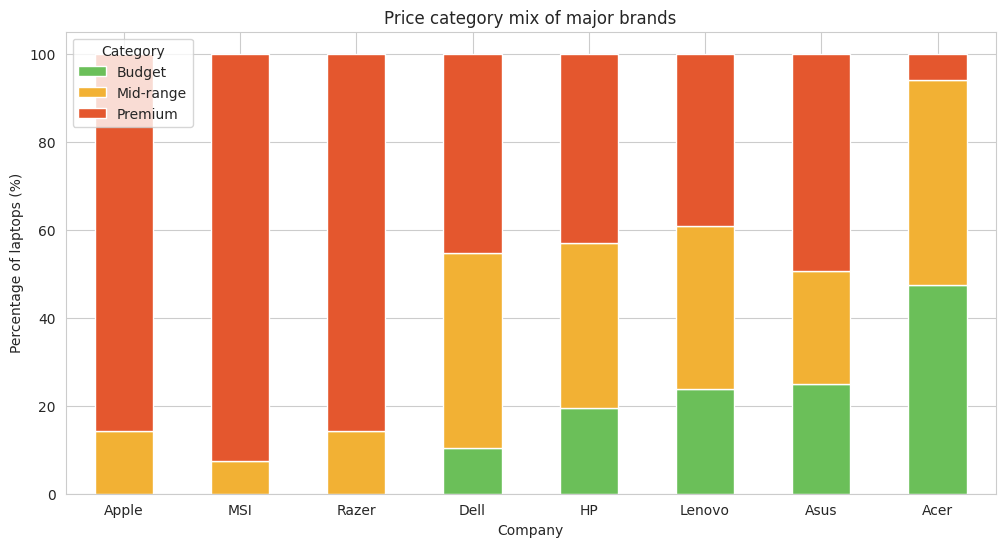

In [44]:
top_brands = ['Apple', 'MSI', 'Razer', 'Dell', 'HP', 'Lenovo', 'Asus', 'Acer']
ct = pd.crosstab(laptop['Company'], laptop['Price_Category'], normalize='index').loc[top_brands, cat_order] * 100

ct.plot(kind='bar', stacked=True, figsize=(12, 6), color=['#6bbf59', '#f2b134', '#e4572e'])
plt.xticks(rotation=0)
plt.xlabel('Company')
plt.ylabel('Percentage of laptops (%)')
plt.title('Price category mix of major brands')
plt.legend(title='Category')
plt.show()

### ***Observation***
### ***Apple (86%), MSI (93%) and Razer (86%) are almost fully Premium.***
### ***Acer is the budget brand: 48% of its laptops are Budget and only 6% are Premium.***
### ***Dell, HP, Lenovo and Asus have laptops in all three categories.***

# **Multivariate Analysis**
* Here we look at **three or more features together**.

## ***1] RAM, laptop type and price together***

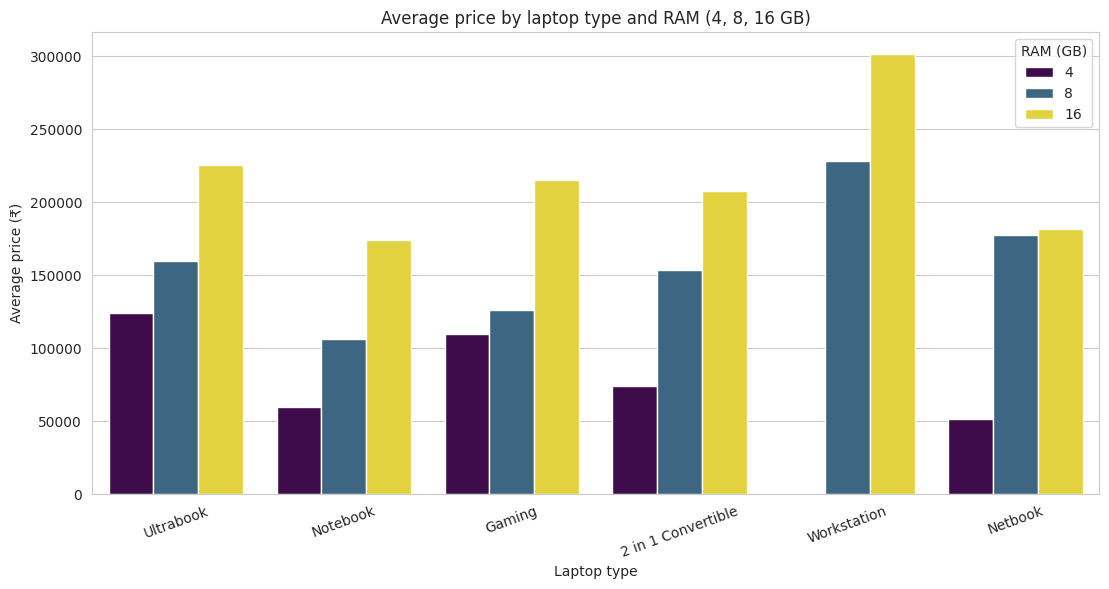

In [45]:
plt.figure(figsize=(13, 6))
sns.barplot(x='TypeName', y='Price_INR', hue='Ram_GB',
            data=laptop[laptop['Ram_GB'].isin([4, 8, 16])], palette='viridis', ci=None)
plt.xticks(rotation=20)
plt.xlabel('Laptop type')
plt.ylabel('Average price (₹)')
plt.title('Average price by laptop type and RAM (4, 8, 16 GB)')
plt.legend(title='RAM (GB)')
plt.show()

### ***Observation***
### ***In every laptop type the price goes up as the RAM goes up.***
### ***At the same RAM, Gaming, Ultrabook and Workstation laptops cost more than a normal Notebook.***

## ***2] CPU series, SSD and price together***

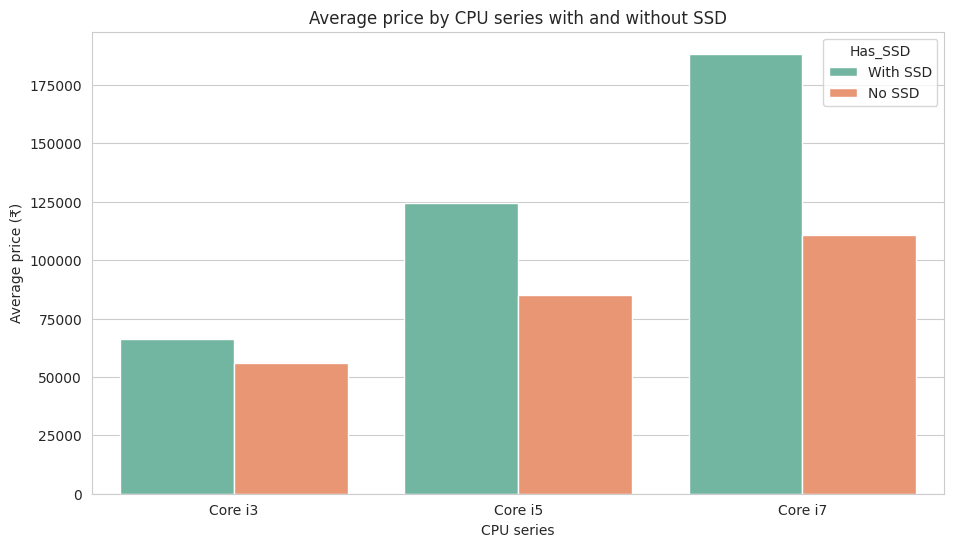

In [46]:
main_cpu = laptop[laptop['Cpu_Series'].isin(['Core i3', 'Core i5', 'Core i7'])]

plt.figure(figsize=(11, 6))
sns.barplot(x='Cpu_Series', y='Price_INR', hue='Has_SSD', data=main_cpu,
            order=['Core i3', 'Core i5', 'Core i7'], palette='Set2', ci=None)
plt.xlabel('CPU series')
plt.ylabel('Average price (₹)')
plt.title('Average price by CPU series with and without SSD')
plt.show()

### ***Observation***
### ***An SSD adds a big amount to the price at every CPU level, and a better CPU adds to the price with or without an SSD.***
### ***The costliest laptops have a Core i7, an SSD and a lot of RAM together.***

## ***3] Price by brand and price category (heatmap of average RAM)***

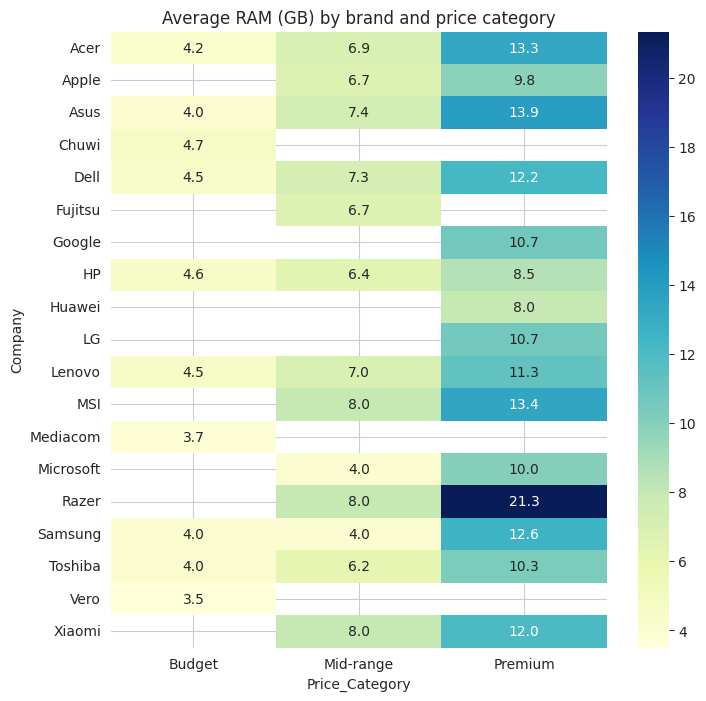

In [47]:
pivot = laptop.pivot_table(index='Company', columns='Price_Category', values='Ram_GB', aggfunc='mean')[cat_order]
plt.figure(figsize=(8, 8))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Average RAM (GB) by brand and price category')
plt.show()

### ***Observation***
### ***In almost every brand the average RAM goes up from Budget to Premium.***
### ***So RAM is a good sign of which price category a laptop belongs to.***

## ***4] Pairplot of the main numeric features***

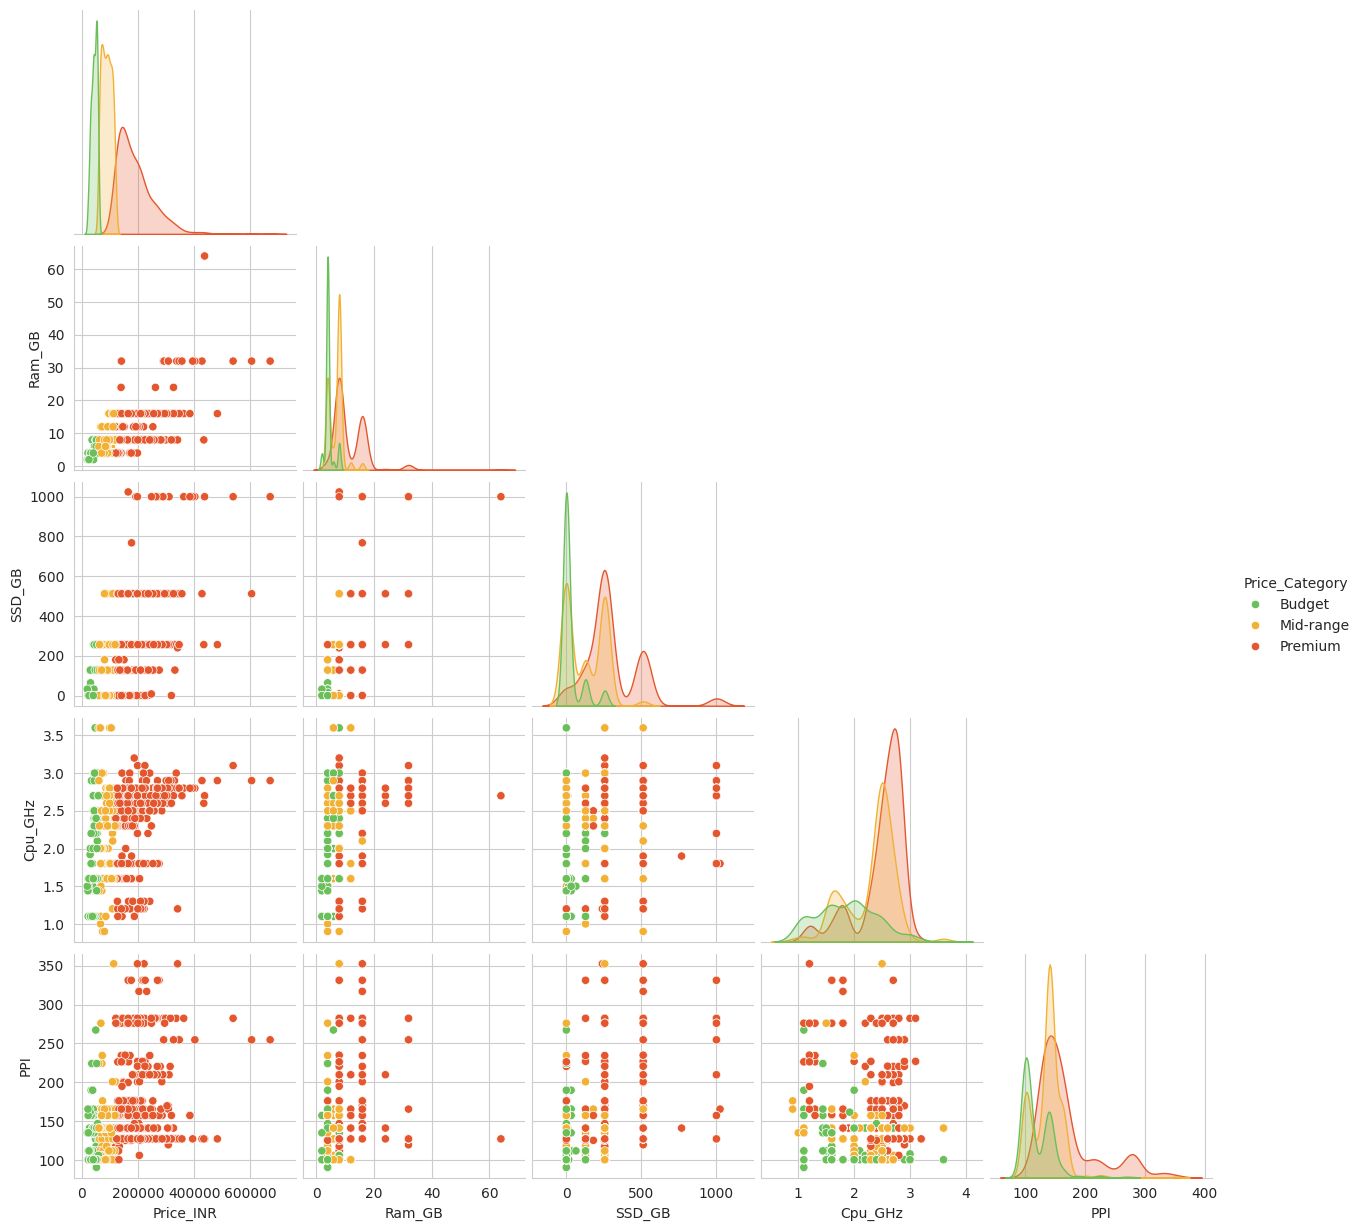

In [48]:
sns.pairplot(laptop[['Price_INR', 'Ram_GB', 'SSD_GB', 'Cpu_GHz', 'PPI', 'Price_Category']],
             hue='Price_Category', hue_order=cat_order,
             palette=['#6bbf59', '#f2b134', '#e4572e'], corner=True)
plt.show()

### ***Observation***
### ***Budget, Mid-range and Premium laptops are fairly well separated on RAM, SSD size and PPI.***
### ***Premium laptops have high values and Budget laptops have low values, so a model should be able to classify them well.***

# **Correlation Analysis**

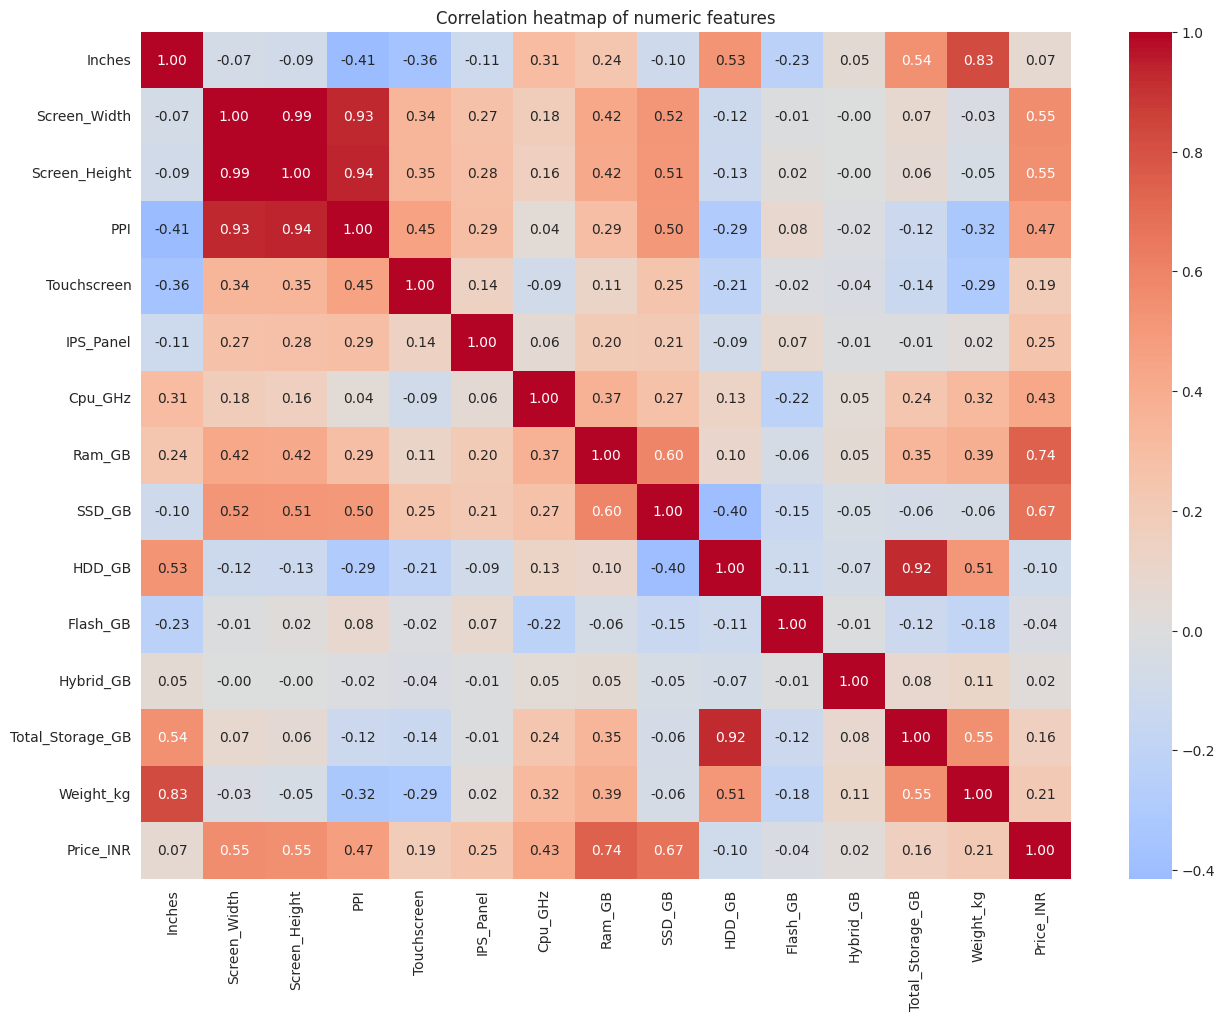

In [49]:
num_cols = laptop.select_dtypes(include='number')

plt.figure(figsize=(15, 11))
sns.heatmap(num_cols.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap of numeric features')
plt.show()

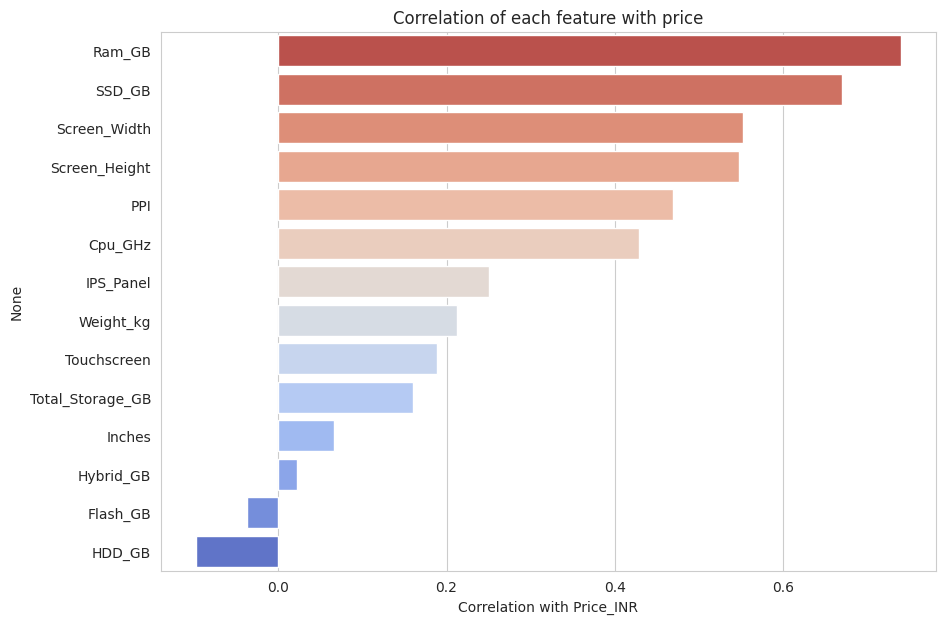

,Price_INR
Ram_GB,0.74
SSD_GB,0.67
Screen_Width,0.55
Screen_Height,0.55
PPI,0.47
Cpu_GHz,0.43
IPS_Panel,0.25
Weight_kg,0.21
Touchscreen,0.19
Total_Storage_GB,0.16


In [50]:
# Which features are most related to Price?
corr_price = num_cols.corr()['Price_INR'].drop('Price_INR').sort_values(ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(x=corr_price.values, y=corr_price.index, palette='coolwarm_r')
plt.xlabel('Correlation with Price_INR')
plt.title('Correlation of each feature with price')
plt.show()

corr_price.round(2)

### ***Observation***
### ***The features most related to price are Ram_GB (0.74), SSD_GB (0.67), Screen_Width and Screen_Height (0.55), PPI (0.47) and Cpu_GHz (0.43).***
### ***Weaker ones are IPS_Panel (0.25), Weight_kg (0.21) and Touchscreen (0.19).***
### ***HDD_GB has a slightly negative value (-0.10), which means laptops with more HDD space are a bit cheaper.***
### ***Screen_Width and Screen_Height are almost the same thing (correlation 0.99), so we can use only one of them in the model.***

# **Outlier Analysis**

In [51]:
Q1 = laptop['Price_INR'].quantile(0.25)
Q3 = laptop['Price_INR'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
outliers = laptop[laptop['Price_INR'] > upper]

print('Upper limit for outliers: ₹', round(upper))
print('Number of price outliers :', len(outliers))
print()
print(outliers['TypeName'].value_counts())
outliers.sort_values('Price_INR', ascending=False)[['Company', 'Product', 'TypeName', 'Ram_GB', 'SSD_GB', 'Price_INR']].head(10)

Upper limit for outliers: ₹ 311052
Number of price outliers : 28

TypeName
Gaming         17
Workstation     6
Notebook        3
Ultrabook       2
Name: count, dtype: int64


,Company,Product,TypeName,Ram_GB,SSD_GB,Price_INR
196,Razer,Blade Pro,Gaming,32,1000,670890
830,Razer,Blade Pro,Gaming,32,512,604890
610,Lenovo,Thinkpad P51,Notebook,32,1000,538890
749,HP,Zbook 17,Workstation,16,256,482790
1066,Asus,ROG G701VO,Gaming,64,1000,437250
1136,HP,ZBook 17,Workstation,8,256,434434
238,Asus,ROG G703VI-E5062T,Gaming,32,512,427900
723,Dell,Alienware 17,Gaming,32,1000,402534
780,Dell,Alienware 17,Gaming,32,1000,394768
1231,Razer,Blade Pro,Gaming,16,1000,384890


### ***Observation***
### ***28 laptops (about 2%) are above ₹3.11 lakh and are treated as price outliers.***
### ***17 of them are Gaming, 6 are Workstations and the other 5 are Notebook or Ultrabook. The costliest one is the Razer Blade Pro (₹6.71 lakh).***
### ***These are real high-end laptops (median RAM 16 GB, up to 64 GB) and not wrong data, so we keep them.***

# **INSIGHTS DRAWN**

1. RAM has the biggest effect on price (correlation 0.74). Average price is ₹63,000 for 4 GB, ₹1.30 lakh for 8 GB and ₹2.14 lakh for 16 GB.
2. An SSD matters more than the storage size. Laptops with an SSD cost almost double (₹1.53 lakh vs ₹70,839), but total storage has only a weak relation with price (0.16).
3. The CPU family decides the price band: Core i7 ₹1.77 lakh, Core i5 ₹1.12 lakh, Core i3 ₹59,715.
4. Laptop type matters. Workstation (₹2.51 lakh), Gaming (₹1.90 lakh) and Ultrabook (₹1.71 lakh) cost much more than a normal Notebook (₹86,762).
5. Apple, MSI and Razer are mostly Premium (86% to 93%), Acer is the budget brand, and Dell, HP, Lenovo and Asus sell in all price ranges.
6. Touchscreen (about ₹41,000 more), IPS panel (about ₹43,000 more) and a sharper screen increase the price. Screen size alone does not.
7. Nvidia laptops average ₹1.65 lakh, compared to ₹1.12 lakh for Intel graphics and ₹85,583 for AMD.
8. macOS laptops average ₹1.72 lakh and Windows laptops ₹1.32 lakh. Laptops with No OS, Linux or Chrome OS are cheap.
9. The three price categories are fairly balanced (20%, 35%, 44%) and can be separated using RAM, SSD and PPI, so the data is good for machine learning.


# **CONCLUSION**

* The price of a laptop mainly depends on RAM, SSD, the processor family, screen sharpness and the laptop type (Gaming, Workstation, Ultrabook).
* Weight, screen size and total storage do not affect the price much on their own.
* Using these specs we should be able to predict the price (regression) and classify a laptop as Budget, Mid-range or Premium (classification).
* Next we will build and compare the models in Orange, and if time permits, make a small web app where a user enters the specs and gets an estimated price in rupees.

# **SUGGESTIONS**

* For buyers: if the budget is limited, go for an SSD and 8 GB RAM instead of a bigger HDD, and pay extra for a touchscreen only if you really need it.
* For sellers: price new models mainly on RAM, SSD and CPU family.
* Future work: add newer laptops with prices in rupees, add features like battery life, and try more models such as Random Forest and Gradient Boosting.
* Limitation: the prices come from an older European dataset converted at 1 EUR = ₹110, so they may not match today's Indian market prices.
